Outline
1. Excel exercise of simple model - interactive formula
2. Build the exercise in GreenLight



### Imports - can ignore

In [1]:
### Imports needed for running the code and other general setup
import os

from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd
import greenlight

C:\Users\katzi001\.conda\envs\intro_gh_modelling\Lib\site-packages\greenlight\_solve\_solve_ivp.py:23: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy (detected version 2.5.1)
  from scipy.integrate import solve_ivp


## Tunnel model in GreenLight

### Defining the model

In [12]:
# Define model variables
tunnel_model = {
    "tau": {
        "description": "Transmissivity (hemispherical) of the cover for sun radiation",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.2",
        "definition": "0.7",
        "type": "const"
    },
    "iSun": {
        "description": "Solar radiation",
        "unit": "W/m2",
        "reference": "Stanghellini et al. (2024), Eq. 3.9",
        "definition": "700",
        "type": "input"
    },
    "fTunnelSky": {
        "description": "View factor between tunnel and sky",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.5",
        "definition": "0.5",
        "type": "const"
    },
    "epsCover": {
        "description": "Emissivity of the cover, including effect of screen(s)",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.3",
        "definition": "1",
        "type": "const"
    },
    "alphaR": {
        "description": "Apparent transfer coefficient for thermal radiation",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.6",
        "definition": "6",
        "type": "const"
    },
    "tSky": {
        "description": "Apparent temperature of the sky (depends, among other things, on cloudiness)",
        "unit": "°C",
        "reference": "Stanghellini et al. (2024), Eq. 3.9",
        "definition": "0",
        "type": "input"
    },
    "tOut": {
        "description": "Temperature of the air outside the greenhouse",
        "unit": "°C",
        "reference": "Stanghellini et al. (2024), Eq. 3.9",
        "definition": "30",
        "type": "input"
    },
    "tSoil": {
        "description": "Temperature of the soil surface",
        "unit": "°C",
        "reference": "Stanghellini et al. (2024), Eq. 3.9",
        "definition": "35",
        "type": "input"
    },
    "fTunnelSoil": {
        "description": "View factor between tunnel and soil",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.5",
        "definition": "0.5",
        "type": "const"
    },
    "epsSoil": {
        "description": "Emissivity of the soil, including possible effect of mulch",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.3",
        "definition": "1",
        "type": "const"
    },
    "aCoverOverSoil": {
        "description": "Surface area of cover per unit surface area of soil",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.7. This variable is used to represent aCover divided by aSoil",
        "definition": "1.2",
        "type": "const"
    },
    "alphaCover": {
        "description": "Heat transfer coefficient of the cover material (including possible screens)",
        "unit": "W/m2/K",
        "reference": "Stanghellini et al. (2024), Eq. 3.7",
        "definition": "6",
        "type": "const"
    },
    "alphaSoil": {
        "description": "Heat transfer coefficient of the soil (including possible mulches)",
        "unit": "W/m2/K",
        "reference": "Stanghellini et al. (2024), Eq. 3.68",
        "definition": "5",
        "type": "const"
    }
}

In [13]:
tunnel_model["tTunnel"] = {
        "description": "Temperature of the unventilated greenhouse",
        "unit": "°C",
        "reference": "Stanghellini et al. (2024), Eq. 3.9 (rearranged to isolate tTunnel)",
        "type": "aux",
        "definition": "(" \
        "tau * iSun " \
        "+ fTunnelSky * epsCover * alphaR * tSky " \
        "+ aCoverOverSoil * alphaCover * tOut " \
        "+ tSoil * (fTunnelSoil * epsSoil * alphaR + alphaSoil)" \
    ") / ( " \
        "fTunnelSky * epsCover * alphaR " \
        "+ aCoverOverSoil * alphaCover " \
        "+ fTunnelSoil * epsSoil * alphaR " \
        "+ alphaSoil " \
    ")"
    }

In [14]:
mdl = greenlight.GreenLight(
    base_path=os.getcwd(), 
    input_prompt=tunnel_model, 
    output_path=os.path.join("output", "output.csv")
)

In [15]:
mdl.run()



Simulation started at time (ISO format): 2026-07-29T11:01:12.423983
Running: 0.00%

Simulation complete at time (ISO format): 2026-07-29T11:01:12.433994
Simulated 1.0 days
Elapsed time: 0.01001119613647461 seconds
Output saved to file output\output.csv
Model structure log saved to output\output_model_struct_log.json
Simulation log saved to output\output_simulation_log.txt


In [16]:
"""Load simulation result"""
output_df = pd.read_csv(os.path.join("output", "output.csv"), header=[0,1,2], low_memory=False)

display(
    output_df.style
      .format("{:.2f}")
      .set_properties(**{"text-align": "left"})
      .set_table_styles([
          {"selector": "th", "props": [("text-align", "left")]}
      ])
)

,Time,iSun,tSky,tOut,tSoil,tTunnel
,no_description,Solar radiation,"Apparent temperature of the sky (depends, among other things, on cloudiness)",Temperature of the air outside the greenhouse,Temperature of the soil surface,Temperature of the unventilated greenhouse
,no_unit_defined,W/m2,°C,°C,°C,°C
0,0.00,700.00,0.00,30.00,35.00,54.18
1,3600.00,700.00,0.00,30.00,35.00,54.18
2,7200.00,700.00,0.00,30.00,35.00,54.18
3,10800.00,700.00,0.00,30.00,35.00,54.18
4,14400.00,700.00,0.00,30.00,35.00,54.18
5,18000.00,700.00,0.00,30.00,35.00,54.18
6,21600.00,700.00,0.00,30.00,35.00,54.18
7,25200.00,700.00,0.00,30.00,35.00,54.18


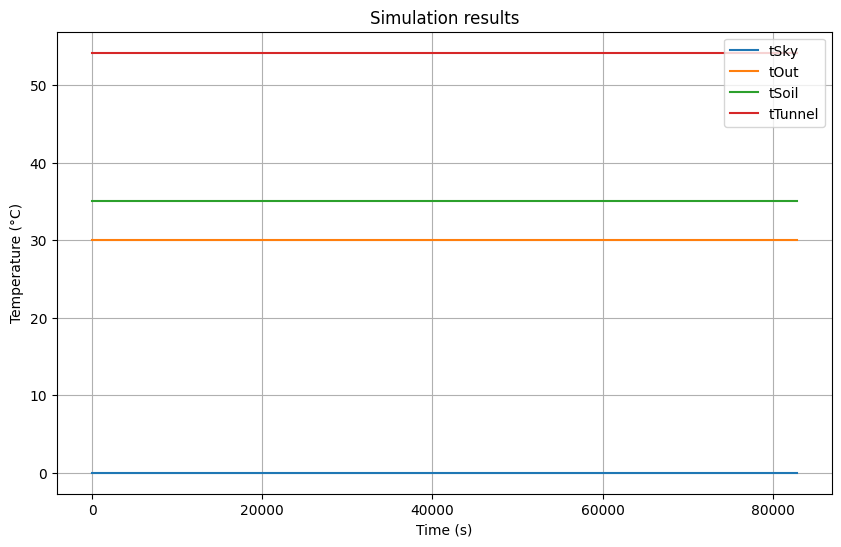

In [17]:
"""Make graphs"""
variable_names = output_df.columns.get_level_values(0)
descriptions = output_df.columns.get_level_values(1)
units = output_df.columns.get_level_values(2)

# Create dictionaries for descriptions and units
descriptions_dict = dict(zip(variable_names, descriptions))
units_dict = dict(zip(variable_names, units))

"""Present results in a graph graphs"""
# Choose variables out of output_df.columns
# For a description of a variable var, see descriptions_dict[var]. For the unit, see units_dict[var]
chosen_vars = ["tSky", "tOut", "tSoil", "tTunnel"]

plt.figure(figsize=(10, 6))

for var in chosen_vars:
    plt.plot(output_df["Time"], output_df[var], label=var)

plt.xlabel("Time (s)")
plt.ylabel("Temperature (°C)")
plt.title("Simulation results")
plt.legend()
plt.grid(True)
plt.show()

In [18]:
# New model
options = {
    "options": {
        "t_start": "0",
        "t_end": str(10 * 24 * 60 * 60)
    }
}

tunnel_model["Time"] = {
      "unit" : "s",
      "type" : "time",
      "description" : "Time since start of data"
   }

tunnel_model["dummy"] = {
        "description": "Dummy variable",
        "unit": "-",
        "reference": "Used to get the model going",
        "type": "state",
        "definition": "0",
        "init": "0"
    }

mdl_2 = greenlight.GreenLight(
    base_path=os.getcwd(), 
    input_prompt=[tunnel_model, os.path.join("input", "example_weather.csv"), options], 
    output_path=os.path.join("output", "output_2.csv")
)
mdl_2.run()



Loading model from input\example_weather.csv
Simulation started at time (ISO format): 2026-07-29T11:01:24.171018
Running: 100.00%

Simulation complete at time (ISO format): 2026-07-29T11:01:24.268445
Simulated 10.0 days
Elapsed time: 0.0974264144897461 seconds
Output saved to file output\output_2.csv
Model structure log saved to output\output_2_model_struct_log.json
Simulation log saved to output\output_2_simulation_log.txt


In [19]:
"""Load simulation result"""
output_2 = pd.read_csv(os.path.join("output", "output_2.csv"), header=[0,1,2], low_memory=False)

display(
    output_2.style
      .format("{:.2f}")
      .set_properties(**{"text-align": "left"})
      .set_table_styles([
          {"selector": "th", "props": [("text-align", "left")]}
      ])
)

,Time,dummy,iSun,tOut,tSky,tSoil,tTunnel
,Time since start of data,Dummy variable,Solar radiation,Temperature of the air outside the greenhouse,"Apparent temperature of the sky (depends, among other things, on cloudiness)",Temperature of the soil surface,Temperature of the unventilated greenhouse
,s,-,W m**-2,°C,°C,°C,°C
0,0.00,0.00,0.00,6.80,-3.05,12.27,7.58
1,3600.00,0.00,0.00,6.39,1.62,12.27,8.18
2,7200.00,0.00,0.00,5.93,2.68,12.26,8.18
3,10800.00,0.00,0.00,5.33,2.05,12.26,7.84
4,14400.00,0.00,0.00,4.77,1.45,12.26,7.51
5,18000.00,0.00,0.00,4.38,1.04,12.25,7.29
6,21600.00,0.00,0.00,4.31,0.97,12.25,7.25
7,25200.00,0.00,0.00,3.96,0.60,12.25,7.05


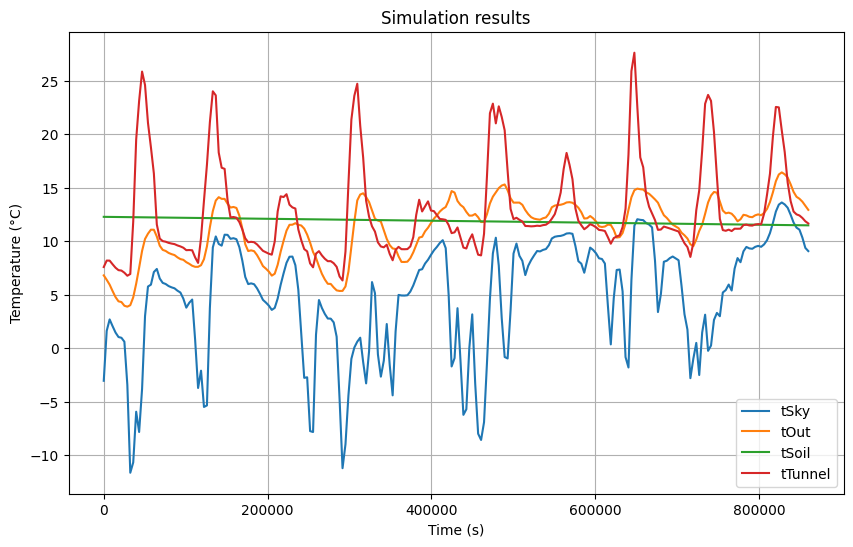

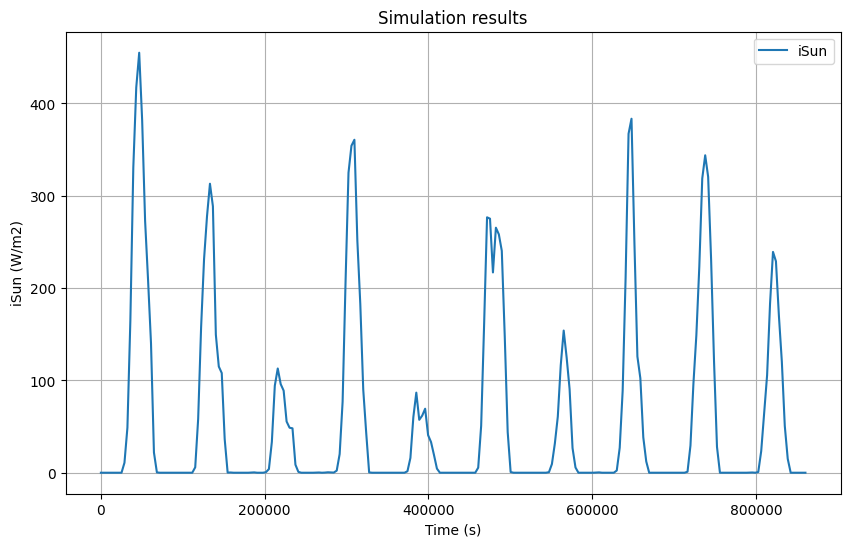

In [20]:
"""Make graphs"""
variable_names = output_2.columns.get_level_values(0)
descriptions = output_2.columns.get_level_values(1)
units = output_2.columns.get_level_values(2)

# Create dictionaries for descriptions and units
descriptions_dict = dict(zip(variable_names, descriptions))
units_dict = dict(zip(variable_names, units))

"""Present results in a graph graphs"""
# Choose variables out of output_df.columns
# For a description of a variable var, see descriptions_dict[var]. For the unit, see units_dict[var]
chosen_vars = ["tSky", "tOut", "tSoil", "tTunnel"]

plt.figure(figsize=(10, 6))

for var in chosen_vars:
    plt.plot(output_2["Time"], output_2[var], label=var)

plt.xlabel("Time (s)")
plt.ylabel("Temperature (°C)")
plt.title("Simulation results")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 6))

plt.plot(output_2["Time"], output_2["iSun"], label="iSun")

plt.xlabel("Time (s)")
plt.ylabel("iSun (W/m2)")
plt.title("Simulation results")
plt.legend()
plt.grid(True)
plt.show()